In [ ]:
import os
import re
import cv2
import pickle
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import nibabel as nib
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import zoom
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
tf.random.set_seed(42)
np.random.seed(42)
random.seed(42)

TARGET_SHAPE = (128, 128, 128)
BATCH_SIZE = 2
EPOCHS = 25
LR = 1e-4
NUM_CLASSES = 4
from google.colab import drive
drive.mount('/content/drive')

BASE_DIR = "/content/drive/MyDrive/Colab Notebooks/lung_cancer"
PATIENTS_CSV = f"{BASE_DIR}/PatientsData.csv"
MANIFEST_CSV = f"/content/drive/MyDrive/Colab Notebooks/processed/manifest_preproc.csv"
LABELS_CSV = f"{BASE_DIR}/labels_TTF1_CK7_Multiclass.csv"
RADIOMICS_DIR = Path(f"{BASE_DIR}/radiomics_ct")
MODEL_PATH = f"{BASE_DIR}/model_ct_radiomics_multiclass.keras"
SCALER_PATH = f"{BASE_DIR}/radiomics_scaler.pkl"

PREFERRED_CT_SOURCE = "cropped_nifti"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_csv(PATIENTS_CSV, sep=";")

def to_tokens(s):
    if pd.isna(s): return []
    s = str(s).upper().replace(" ", "")
    if s in ("", "NONE", "NAN"): return []
    return [t for t in s.split(",") if t]

def has_any(token_list, keys):
    return int(any(tok in token_list for tok in keys))


tokens_series = df["Biopsy positive"].apply(to_tokens)
codes = df["Code"].astype(str).str.extract(r"(\d+)")[0]

TTF1 = tokens_series.apply(lambda toks: has_any(toks, {"TTF1"}))
CK7 = tokens_series.apply(lambda toks: has_any(toks, {"CK7"}))

mask_missing = df["Biopsy positive"].isna() | (df["Biopsy positive"].astype(str).str.strip() == "")
TTF1 = TTF1.mask(mask_missing)
CK7 = CK7.mask(mask_missing)

df_labels = pd.DataFrame({
    "Code": codes,
    "TTF1": TTF1.astype("Int64"),
    "CK7": CK7.astype("Int64")
})

def get_multiclass_label(row):
    if pd.isna(row['TTF1']) or pd.isna(row['CK7']):
        return np.nan

    t = int(row['TTF1'])
    c = int(row['CK7'])

    if t == 0 and c == 0: return 0
    if t == 1 and c == 0: return 1
    if t == 0 and c == 1: return 2
    if t == 1 and c == 1: return 3
    return np.nan

df_labels['ClassID'] = df_labels.apply(get_multiclass_label, axis=1).astype("Int64")

df_labels = df_labels.dropna(subset=['ClassID'])
print("Distribuție Clase (0-3):")
print(df_labels['ClassID'].value_counts().sort_index())

df_labels.to_csv(LABELS_CSV, index=False)
display(df_labels.head())

Distribuție Clase (0-3):
ClassID
0    14
1    31
2    12
3    30
Name: count, dtype: Int64


,Code,TTF1,CK7,ClassID
0,2011,1,0,1
1,3111,1,1,3
2,4111,1,0,1
3,5111,0,0,0
4,7011,0,0,0


In [ ]:
def _norm_code(x: str) -> str:
    return pd.Series([x]).astype(str).str.extract(r"(\d+)")[0].iloc[0]

def _pick_ct_path(row, preferred="cropped_nifti"):
    candidates_order = {
        "cropped_nifti": ["ct_cropped_nifti_path", "ct_nifti_path"],
        "nifti": ["ct_nifti_path", "ct_cropped_nifti_path"],
    }.get(preferred, ["ct_cropped_nifti_path"])

    for col in candidates_order:
        if col in row and pd.notna(row[col]) and str(row[col]).strip():
            p = str(row[col]).strip()
            if os.path.exists(p):
                return col, p
    return None, None

def load_ct_volume(ct_path, target_shape=TARGET_SHAPE):
    img = nib.load(ct_path)
    vol = img.get_fdata().astype(np.float32)
    vol = np.nan_to_num(vol)

    p1, p99 = np.percentile(vol, [1, 99])
    if p99 > p1:
        vol = np.clip((vol - p1) / (p99 - p1), 0, 1)
    else:
        vol = (vol - vol.min()) / (vol.max() - vol.min() + 1e-6)

    factors = (
        target_shape[0] / vol.shape[0],
        target_shape[1] / vol.shape[1],
        target_shape[2] / vol.shape[2]
    )
    vol_resized = zoom(vol, factors, order=1)
    vol_resized = vol_resized[..., np.newaxis]
    return vol_resized

def load_radiomics_features(path):
    feats = {}
    if not os.path.exists(path): return feats
    with open(path, "r") as f:
        for line in f:
            if ":" not in line: continue
            k, v = line.strip().split(":", 1)
            try:
                v_clean = v.replace("np.float64(", "").replace(")", "").strip()
                if k.strip().startswith("original_"):
                    feats[k.strip()] = float(v_clean)
            except: continue
    return feats

In [ ]:
labels_df = pd.read_csv(LABELS_CSV, dtype={'Code': str})
labels_df['Code'] = labels_df['Code'].apply(_norm_code)

manifest_df = pd.read_csv(MANIFEST_CSV, dtype={'Code': str})
manifest_df.columns = [c.strip() for c in manifest_df.columns]
if "Code" not in manifest_df.columns:
    alt = [c for c in manifest_df.columns if c.lower() == "code"]
    if alt: manifest_df.rename(columns={alt[0]: "Code"}, inplace=True)
manifest_df['Code'] = manifest_df['Code'].apply(_norm_code)

data_index = labels_df.merge(manifest_df, on="Code", how="inner")

valid_rows = []
for _, row in data_index.iterrows():
    col, path = _pick_ct_path(row, PREFERRED_CT_SOURCE)

    rad_path = RADIOMICS_DIR / f"{row['Code']}_radiomics.txt"

    if path and os.path.exists(path) and rad_path.exists():
        row['ct_path'] = path
        row['radiomics_path'] = str(rad_path)
        valid_rows.append(row)

final_index = pd.DataFrame(valid_rows)
print(f"Pacienți valizi (CT + Radiomics + Labels): {len(final_index)}")
display(final_index[['Code', 'ClassID', 'ct_path']].head())

Pacienți valizi (CT + Radiomics + Labels): 87


,Code,ClassID,ct_path
0,2011,1,/content/drive/MyDrive/Colab Notebooks/process...
1,3111,3,/content/drive/MyDrive/Colab Notebooks/process...
2,4111,1,/content/drive/MyDrive/Colab Notebooks/process...
3,5111,0,/content/drive/MyDrive/Colab Notebooks/process...
4,7011,0,/content/drive/MyDrive/Colab Notebooks/process...


In [ ]:
all_features = []
for _, row in final_index.iterrows():
    feats = load_radiomics_features(row['radiomics_path'])
    feats['Code'] = row['Code']
    all_features.append(feats)

radio_df = pd.DataFrame(all_features).fillna(0.0)

merged_df = final_index.merge(radio_df, on="Code", how="left")

feature_cols = [c for c in radio_df.columns if c.startswith("original_")]
X_radio = merged_df[feature_cols].values.astype(np.float32)

scaler = StandardScaler()
X_radio = scaler.fit_transform(X_radio)

import joblib
joblib.dump(scaler, SCALER_PATH)
print(f"Radiomics shape: {X_radio.shape}")

Radiomics shape: (87, 107)


In [ ]:
ct_paths = merged_df['ct_path'].values
y_labels = merged_df['ClassID'].values.astype(np.int32)
codes = merged_df['Code'].values

X_idx = np.arange(len(ct_paths))

train_idx, temp_idx = train_test_split(X_idx, test_size=0.3, stratify=y_labels, random_state=42)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.5, stratify=y_labels[temp_idx], random_state=42)

print(f"Train: {len(train_idx)}, Val: {len(val_idx)}, Test: {len(test_idx)}")

def multimodal_generator(indices, paths, radios, labels):
    for i in indices:
        vol = load_ct_volume(paths[i])
        rad = radios[i]
        lbl = labels[i]
        yield (vol, rad), lbl

def create_dataset(indices, paths, radios, labels, training=False):
    ds = tf.data.Dataset.from_generator(
        lambda: multimodal_generator(indices, paths, radios, labels),
        output_signature=(
            (
                tf.TensorSpec(shape=TARGET_SHAPE+(1,), dtype=tf.float32),
                tf.TensorSpec(shape=(radios.shape[1],), dtype=tf.float32)
            ),
            tf.TensorSpec(shape=(), dtype=tf.int32)
        )
    )
    if training:
        ds = ds.shuffle(len(indices))
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = create_dataset(train_idx, ct_paths, X_radio, y_labels, training=True)
val_ds = create_dataset(val_idx, ct_paths, X_radio, y_labels, training=False)
test_ds = create_dataset(test_idx, ct_paths, X_radio, y_labels, training=False)

Train: 60, Val: 13, Test: 14


In [ ]:
def conv3d_block(x, filters):
    x = tf.keras.layers.Conv3D(filters, 3, padding="same")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    return x

def build_multiclass_model(radio_dim, input_shape):
    in_ct = tf.keras.Input(shape=input_shape, name="ct_input")
    x = conv3d_block(in_ct, 16)
    x = tf.keras.layers.MaxPool3D(2)(x)

    x = conv3d_block(x, 32)
    x = tf.keras.layers.MaxPool3D(2)(x)

    x = conv3d_block(x, 64)
    x = tf.keras.layers.MaxPool3D(2)(x)

    x = conv3d_block(x, 128)
    x = tf.keras.layers.GlobalAveragePooling3D()(x)

    x = tf.keras.layers.Dense(64, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.3)(x)

    in_radio = tf.keras.Input(shape=(radio_dim,), name="radio_input")
    r = tf.keras.layers.Dense(128, activation="relu")(in_radio)
    r = tf.keras.layers.Dropout(0.3)(r)
    r = tf.keras.layers.Dense(64, activation="relu")(r)

    z = tf.keras.layers.Concatenate()([x, r])
    z = tf.keras.layers.Dense(64, activation="relu")(z)
    z = tf.keras.layers.Dropout(0.3)(z)

    out = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax", name="class_output")(z)

    model = tf.keras.Model(inputs=[in_ct, in_radio], outputs=out)

    return model

model = build_multiclass_model(radio_dim=X_radio.shape[1], input_shape=TARGET_SHAPE+(1,))

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR),
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ct_input            │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 128, 1)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d (Conv3D)     │ (None, 128, 128,  │        448 │ ct_input[0][0]    │
│                     │ 128, 16)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128, 128,  │         64 │ conv3d[0][0]      │
│ (BatchNormalizatio… │ 128, 16)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128, 16)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d       │ (None, 64, 64,    │          0 │ activation[0][0]  │
│ (MaxPooling3D)      │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_1 (Conv3D)   │ (None, 64, 64,    │     13,856 │ max_pooling3d[0]… │
│                     │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        128 │ conv3d_1[0][0]    │
│ (BatchNormalizatio… │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_1     │ (None, 32, 32,    │          0 │ activation_1[0][… │
│ (MaxPooling3D)      │ 32, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_2 (Conv3D)   │ (None, 32, 32,    │     55,360 │ max_pooling3d_1[… │
│                     │ 32, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        256 │ conv3d_2[0][0]    │
│ (BatchNormalizatio… │ 32, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_2     │ (None, 16, 16,    │          0 │ activation_2[0][… │
│ (MaxPooling3D)      │ 16, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_3 (Conv3D)   │ (None, 16, 16,    │    221,312 │ max_pooling3d_2[… │
│                     │ 16, 128)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        512 │ conv3d_3[0][0]    │
│ (BatchNormalizatio… │ 16, 128)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 16, 128)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ radio_input         │ (None, 107)       │          0 │ -               

 Total params: 330,788 (1.26 MB)

 Trainable params: 330,308 (1.26 MB)

 Non-trainable params: 480 (1.88 KB)

In [ ]:
callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss", save_best_only=True)
]

from sklearn.utils import class_weight
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_labels[train_idx]),
    y=y_labels[train_idx]
)
class_weight_dict = dict(enumerate(class_weights))
print("Ponderi clase:", class_weight_dict)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    class_weight=class_weight_dict
)

Ponderi clase: {0: np.float64(1.5), 1: np.float64(0.7142857142857143), 2: np.float64(1.875), 3: np.float64(0.7142857142857143)}
Epoch 1/25
     30/Unknown 104s 99ms/step - loss: 1.7415 - sparse_categorical_accuracy: 0.2060

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


30/30 ━━━━━━━━━━━━━━━━━━━━ 123s 774ms/step - loss: 1.7332 - sparse_categorical_accuracy: 0.2058 - val_loss: 1.4292 - val_sparse_categorical_accuracy: 0.0000e+00 - learning_rate: 1.0000e-04
Epoch 2/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 28s 261ms/step - loss: 1.4585 - sparse_categorical_accuracy: 0.3447 - val_loss: 1.4411 - val_sparse_categorical_accuracy: 0.0769 - learning_rate: 1.0000e-04
Epoch 3/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 30s 253ms/step - loss: 1.3491 - sparse_categorical_accuracy: 0.2285 - val_loss: 1.4458 - val_sparse_categorical_accuracy: 0.0769 - learning_rate: 1.0000e-04
Epoch 4/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - loss: 1.3829 - sparse_categorical_accuracy: 0.1568
Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
30/30 ━━━━━━━━━━━━━━━━━━━━ 30s 254ms/step - loss: 1.3834 - sparse_categorical_accuracy: 0.1588 - val_loss: 1.4323 - val_sparse_categorical_accuracy: 0.2308 - learning_rate: 1.0000e-04
Epoch 5/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 30s 277ms/step - l

In [ ]:
print(f"Generare predicții detaliate pentru cei {len(test_idx)} pacienți din setul de Test...")

patient_results = []
class_mapping = {
    0: "TTF1-/CK7-",
    1: "TTF1+/CK7-",
    2: "TTF1-/CK7+",
    3: "TTF1+/CK7+"
}

for idx in test_idx:
    patient_code = codes[idx]
    true_label_id = y_labels[idx]

    vol = load_ct_volume(ct_paths[idx])
    rad = X_radio[idx]

    vol_batch = np.expand_dims(vol, axis=0)
    rad_batch = np.expand_dims(rad, axis=0)

    pred_probs = model.predict([vol_batch, rad_batch], verbose=0)
    pred_label_id = np.argmax(pred_probs)
    confidence = np.max(pred_probs)

    is_correct = (true_label_id == pred_label_id)

    patient_results.append({
        "Code": patient_code,
        "True ID": true_label_id,
        "Pred ID": pred_label_id,
        "True Label": class_mapping[true_label_id],
        "Pred Label": class_mapping[pred_label_id],
        "Correct": "correct" if is_correct else "false",
        "Conf. (%)": f"{confidence * 100:.1f}%"
    })

df_eval = pd.DataFrame(patient_results)

def highlight_errors(s):
    return ['background-color: #ffcccc' if v == 'false' else 'background-color: #ccffcc' for v in s]

print("\nRezultate Detaliate:")
display(df_eval.style.apply(highlight_errors, subset=['Correct']))

csv_path = f"{BASE_DIR}/test_results_detailed.csv"
df_eval.to_csv(csv_path, index=False)
print(f"\nRaport salvat în: {csv_path}")

Generare predicții detaliate pentru cei 14 pacienți din setul de Test...

Rezultate Detaliate:


,Code,True ID,Pred ID,True Label,Pred Label,Correct,Conf. (%)
0,74111,3,1,TTF1+/CK7+,TTF1+/CK7-,false,36.6%
1,25111,0,3,TTF1-/CK7-,TTF1+/CK7+,false,30.3%
2,10111,1,3,TTF1+/CK7-,TTF1+/CK7+,false,32.3%
3,73111,0,0,TTF1-/CK7-,TTF1-/CK7-,correct,34.5%
4,8011,3,1,TTF1+/CK7+,TTF1+/CK7-,false,30.6%
5,63111,2,3,TTF1-/CK7+,TTF1+/CK7+,false,32.5%
6,4111,1,0,TTF1+/CK7-,TTF1-/CK7-,false,45.2%
7,98011,3,1,TTF1+/CK7+,TTF1+/CK7-,false,29.7%
8,32111,2,3,TTF1-/CK7+,TTF1+/CK7+,false,28.3%
9,102111,1,1,TTF1+/CK7-,TTF1+/CK7-,correct,30.5%



Raport salvat în: /content/drive/MyDrive/Colab Notebooks/lung_cancer/test_results_detailed.csv


7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 764ms/step - loss: 1.4270 - sparse_categorical_accuracy: 0.1775
Test Loss: 1.3821, Test Accuracy: 0.2143


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


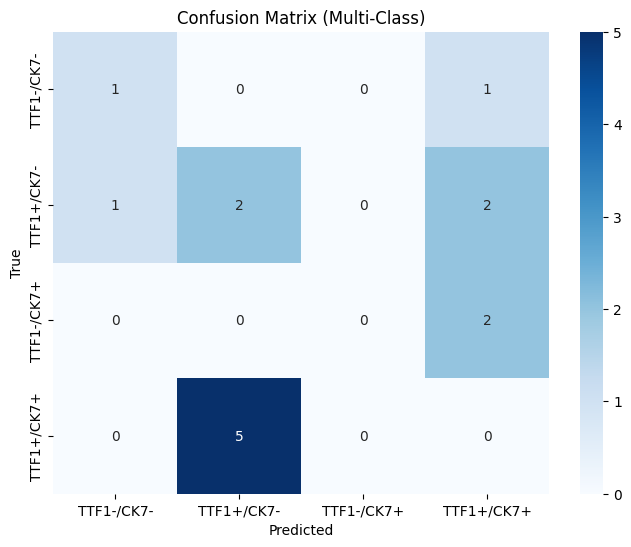


Classification Report:

              precision    recall  f1-score   support

  TTF1-/CK7-       0.50      0.50      0.50         2
  TTF1+/CK7-       0.29      0.40      0.33         5
  TTF1-/CK7+       0.00      0.00      0.00         2
  TTF1+/CK7+       0.00      0.00      0.00         5

    accuracy                           0.21        14
   macro avg       0.20      0.23      0.21        14
weighted avg       0.17      0.21      0.19        14



In [ ]:
loss, acc = model.evaluate(test_ds)
print(f"Test Loss: {loss:.4f}, Test Accuracy: {acc:.4f}")

y_true = []
y_pred_probs = []

for (vol, rad), lbl in test_ds:
    preds = model.predict((vol, rad), verbose=0)
    y_true.extend(lbl.numpy())
    y_pred_probs.extend(preds)

y_true = np.array(y_true)
y_pred_probs = np.array(y_pred_probs)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

class_names = ["TTF1-/CK7-", "TTF1+/CK7-", "TTF1-/CK7+", "TTF1+/CK7+"]

cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (Multi-Class)')
plt.show()

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred_classes, target_names=class_names, zero_division=0))

Căutăm threshold-urile optime pentru fiecare clasă...
Clasa TTF1-/CK7-: Best Threshold = 0.345 (Max F1: 0.50)
Clasa TTF1+/CK7-: Best Threshold = 0.199 (Max F1: 0.53)
Clasa TTF1-/CK7+: Best Threshold = 0.225 (Max F1: 0.80)
Clasa TTF1+/CK7+: Best Threshold = 0.210 (Max F1: 0.53)

 Aplicare threshold-uri optimizate...

--- RAPORT CLASIFICARE (Cu Threshold-uri Optimizate) ---
              precision    recall  f1-score   support

  TTF1-/CK7-       0.50      0.50      0.50         2
  TTF1+/CK7-       0.29      0.40      0.33         5
  TTF1-/CK7+       0.00      0.00      0.00         2
  TTF1+/CK7+       0.00      0.00      0.00         5

    accuracy                           0.21        14
   macro avg       0.20      0.23      0.21        14
weighted avg       0.17      0.21      0.19        14



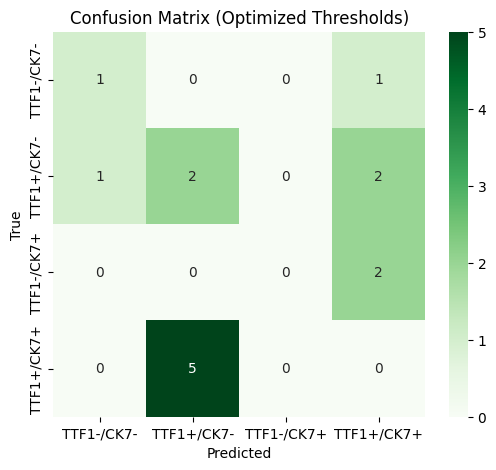

In [ ]:
from sklearn.metrics import precision_recall_curve

print("Căutăm threshold-urile optime pentru fiecare clasă...")

y_pred_probs_all = []
y_true_all = []

for (vol, rad), lbl in test_ds:
    preds = model.predict((vol, rad), verbose=0)
    y_pred_probs_all.extend(preds)
    y_true_all.extend(lbl.numpy())

y_pred_probs_all = np.array(y_pred_probs_all)
y_true_all = np.array(y_true_all)

class_names = ["TTF1-/CK7-", "TTF1+/CK7-", "TTF1-/CK7+", "TTF1+/CK7+"]
best_thresholds = {}

for class_id in range(NUM_CLASSES):
    y_true_binary = (y_true_all == class_id).astype(int)
    y_prob_class = y_pred_probs_all[:, class_id]

    precisions, recalls, thresholds = precision_recall_curve(y_true_binary, y_prob_class)

    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)

    best_idx = np.argmax(f1_scores)
    best_thresh = thresholds[best_idx] if best_idx < len(thresholds) else 0.5
    best_f1 = f1_scores[best_idx]

    best_thresholds[class_id] = best_thresh
    print(f"Clasa {class_names[class_id]}: Best Threshold = {best_thresh:.3f} (Max F1: {best_f1:.2f})")

print("\n Aplicare threshold-uri optimizate...")

final_predictions = []

for probs in y_pred_probs_all:
    candidates = []
    for class_id in range(NUM_CLASSES):
        if probs[class_id] >= best_thresholds[class_id]:
            candidates.append((class_id, probs[class_id]))

    if not candidates:
        final_predictions.append(np.argmax(probs))
    else:
        candidates.sort(key=lambda x: x[1], reverse=True)
        final_predictions.append(candidates[0][0])

print("\n--- RAPORT CLASIFICARE (Cu Threshold-uri Optimizate) ---")
print(classification_report(y_true_all, final_predictions, target_names=class_names, zero_division=0))

cm_new = confusion_matrix(y_true_all, final_predictions)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_new, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix (Optimized Thresholds)')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.show()

In [ ]:

def augment_volume(volume):
    volume = tf.convert_to_tensor(volume)

    seed = (random.randint(0, 1000), random.randint(0, 1000))
    volume = tf.image.stateless_random_flip_left_right(volume, seed=seed)
    volume = tf.image.stateless_random_flip_up_down(volume, seed=seed)

    k = random.randint(0, 3)
    volume = tf.image.rot90(volume, k=k)

    return volume

def multimodal_generator(indices, paths, radios, labels, augment=False):
    for i in indices:
        vol = load_ct_volume(paths[i])
        rad = radios[i]
        lbl = labels[i]

        if augment:
            vol = augment_volume(vol)

        yield (vol, rad), lbl

def create_dataset(indices, paths, radios, labels, training=False):
    ds = tf.data.Dataset.from_generator(
        lambda: multimodal_generator(indices, paths, radios, labels, augment=training),
        output_signature=(
            (
                tf.TensorSpec(shape=TARGET_SHAPE+(1,), dtype=tf.float32),
                tf.TensorSpec(shape=(radios.shape[1],), dtype=tf.float32)
            ),
            tf.TensorSpec(shape=(), dtype=tf.int32)
        )
    )
    if training:
        ds = ds.shuffle(len(indices))
        ds = ds.repeat()

    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = create_dataset(train_idx, ct_paths, X_radio, y_labels, training=True)
val_ds = create_dataset(val_idx, ct_paths, X_radio, y_labels, training=False)
test_ds = create_dataset(test_idx, ct_paths, X_radio, y_labels, training=False)

print("Dataset-uri recreate cu Data Augmentation activat pe Train.")

Dataset-uri recreate cu Data Augmentation activat pe Train.


In [ ]:
from sklearn.utils import class_weight

unique_classes = np.unique(y_labels[train_idx])
class_weights_calc = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=unique_classes,
    y=y_labels[train_idx]
)
class_weight_dict = dict(zip(unique_classes, class_weights_calc))

print("Ponderi calculate:", class_weight_dict)

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, verbose=1, min_lr=1e-6),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss", save_best_only=True)
]

steps_per_epoch = len(train_idx) // BATCH_SIZE

print(f"Start Training pentru {EPOCHS} epoci...")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    steps_per_epoch=steps_per_epoch,
    callbacks=callbacks,
    class_weight=class_weight_dict
)

Ponderi calculate: {np.int32(0): np.float64(1.5), np.int32(1): np.float64(0.7142857142857143), np.int32(2): np.float64(1.875), np.int32(3): np.float64(0.7142857142857143)}
Start Training pentru 25 epoci...
Epoch 1/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 69s 1s/step - loss: 1.4744 - sparse_categorical_accuracy: 0.2572 - val_loss: 1.4547 - val_sparse_categorical_accuracy: 0.1538 - learning_rate: 1.0000e-04
Epoch 2/25


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


30/30 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - loss: 1.6451 - sparse_categorical_accuracy: 0.1590 - val_loss: 1.4530 - val_sparse_categorical_accuracy: 0.1538 - learning_rate: 1.0000e-04
Epoch 3/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 24s 832ms/step - loss: 1.4821 - sparse_categorical_accuracy: 0.1768 - val_loss: 1.4460 - val_sparse_categorical_accuracy: 0.2308 - learning_rate: 1.0000e-04
Epoch 4/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 27s 942ms/step - loss: 1.5611 - sparse_categorical_accuracy: 0.2408 - val_loss: 1.4460 - val_sparse_categorical_accuracy: 0.3077 - learning_rate: 1.0000e-04
Epoch 5/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 27s 930ms/step - loss: 1.4507 - sparse_categorical_accuracy: 0.3320 - val_loss: 1.4476 - val_sparse_categorical_accuracy: 0.3077 - learning_rate: 1.0000e-04
Epoch 6/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 28s 946ms/step - loss: 1.3762 - sparse_categorical_accuracy: 0.2118 - val_loss: 1.4500 - val_sparse_categorical_accuracy: 0.3077 - learning_rate: 1.0000e-04
Epoch 7/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 3

In [ ]:
print(f"Generare predicții detaliate pentru cei {len(test_idx)} pacienți din setul de Test...")

patient_results = []
class_mapping = {
    0: "TTF1-/CK7-",
    1: "TTF1+/CK7-",
    2: "TTF1-/CK7+",
    3: "TTF1+/CK7+"
}

for idx in test_idx:
    patient_code = codes[idx]
    true_label_id = y_labels[idx]

    vol = load_ct_volume(ct_paths[idx])
    rad = X_radio[idx]

    vol_batch = np.expand_dims(vol, axis=0)
    rad_batch = np.expand_dims(rad, axis=0)

    pred_probs = model.predict([vol_batch, rad_batch], verbose=0)
    pred_label_id = np.argmax(pred_probs)
    confidence = np.max(pred_probs)

    is_correct = (true_label_id == pred_label_id)

    patient_results.append({
        "Code": patient_code,
        "True ID": true_label_id,
        "Pred ID": pred_label_id,
        "True Label": class_mapping[true_label_id],
        "Pred Label": class_mapping[pred_label_id],
        "Correct": "correct" if is_correct else "false",
        "Conf. (%)": f"{confidence * 100:.1f}%"
    })

df_eval = pd.DataFrame(patient_results)

def highlight_errors(s):
    return ['background-color: #ffcccc' if v == 'false' else 'background-color: #ccffcc' for v in s]

print("\nRezultate Detaliate:")
display(df_eval.style.apply(highlight_errors, subset=['Correct']))

csv_path = f"{BASE_DIR}/test_results_detailed.csv"
df_eval.to_csv(csv_path, index=False)
print(f"\nRaport salvat în: {csv_path}")

Generare predicții detaliate pentru cei 14 pacienți din setul de Test...

Rezultate Detaliate:


,Code,True ID,Pred ID,True Label,Pred Label,Correct,Conf. (%)
0,74111,3,3,TTF1+/CK7+,TTF1+/CK7+,correct,27.8%
1,25111,0,2,TTF1-/CK7-,TTF1-/CK7+,false,29.3%
2,10111,1,0,TTF1+/CK7-,TTF1-/CK7-,false,32.3%
3,73111,0,3,TTF1-/CK7-,TTF1+/CK7+,false,30.8%
4,8011,3,0,TTF1+/CK7+,TTF1-/CK7-,false,29.8%
5,63111,2,0,TTF1-/CK7+,TTF1-/CK7-,false,34.4%
6,4111,1,3,TTF1+/CK7-,TTF1+/CK7+,false,36.0%
7,98011,3,0,TTF1+/CK7+,TTF1-/CK7-,false,34.8%
8,32111,2,3,TTF1-/CK7+,TTF1+/CK7+,false,28.7%
9,102111,1,0,TTF1+/CK7-,TTF1-/CK7-,false,33.2%



Raport salvat în: /content/drive/MyDrive/Colab Notebooks/lung_cancer/test_results_detailed.csv


7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 832ms/step - loss: 1.4418 - sparse_categorical_accuracy: 0.1710
Test Loss: 1.5008, Test Accuracy: 0.0714


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


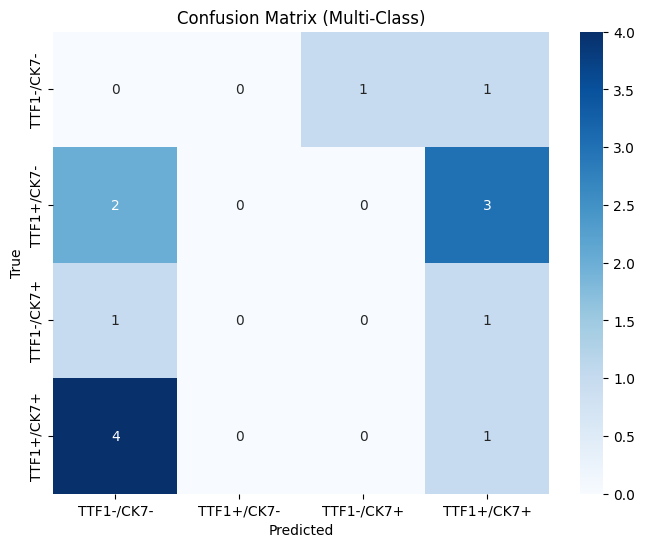


Classification Report:

              precision    recall  f1-score   support

  TTF1-/CK7-       0.00      0.00      0.00         2
  TTF1+/CK7-       0.00      0.00      0.00         5
  TTF1-/CK7+       0.00      0.00      0.00         2
  TTF1+/CK7+       0.17      0.20      0.18         5

    accuracy                           0.07        14
   macro avg       0.04      0.05      0.05        14
weighted avg       0.06      0.07      0.06        14



In [ ]:
loss, acc = model.evaluate(test_ds)
print(f"Test Loss: {loss:.4f}, Test Accuracy: {acc:.4f}")

y_true = []
y_pred_probs = []

for (vol, rad), lbl in test_ds:
    preds = model.predict((vol, rad), verbose=0)
    y_true.extend(lbl.numpy())
    y_pred_probs.extend(preds)

y_true = np.array(y_true)
y_pred_probs = np.array(y_pred_probs)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

class_names = ["TTF1-/CK7-", "TTF1+/CK7-", "TTF1-/CK7+", "TTF1+/CK7+"]

cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (Multi-Class)')
plt.show()

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred_classes, target_names=class_names, zero_division=0))

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif

all_features = []
for _, row in final_index.iterrows():
    feats = load_radiomics_features(row['radiomics_path'])
    feats['Code'] = row['Code']
    all_features.append(feats)

radio_df = pd.DataFrame(all_features).fillna(0.0)
merged_df = final_index.merge(radio_df, on="Code", how="left")

feature_cols = [c for c in radio_df.columns if c.startswith("original_")]
X_raw = merged_df[feature_cols].values.astype(np.float32)
y_temp = merged_df['ClassID'].values.astype(np.int32)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print(f"Features inițiale: {X_scaled.shape[1]}")

selector = SelectKBest(f_classif, k=20)
X_radio = selector.fit_transform(X_scaled, y_temp)

print(f"Features selectate: {X_radio.shape[1]}")
selected_indices = selector.get_support(indices=True)
print("Top features:", [feature_cols[i] for i in selected_indices[:5]])

import joblib
joblib.dump(scaler, SCALER_PATH)
joblib.dump(selector, f"{BASE_DIR}/feature_selector.pkl")

Features inițiale: 107
Features selectate: 20
Top features: ['original_shape_Flatness', 'original_shape_LeastAxisLength', 'original_firstorder_10Percentile', 'original_firstorder_90Percentile', 'original_firstorder_Energy']


/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [ 17  30  32  33  34  35  36  37  38  39  40  41  42  43  44  45  46  47
  48  49  50  51  52  53  54  55  61  62  66  71  72  73  77  87  88  89
  93 102 103 104 105 106] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


['/content/drive/MyDrive/Colab Notebooks/lung_cancer/feature_selector.pkl']

In [ ]:
def build_tiny_model(radio_dim, input_shape):
    in_ct = tf.keras.Input(shape=input_shape, name="ct_input")

    x = tf.keras.layers.Conv3D(8, 3, padding="same", activation="relu")(in_ct)
    x = tf.keras.layers.MaxPooling3D(2)(x)

    x = tf.keras.layers.Conv3D(16, 3, padding="same", activation="relu")(x)
    x = tf.keras.layers.MaxPooling3D(2)(x)

    x = tf.keras.layers.Conv3D(32, 3, padding="same", activation="relu")(x)
    x = tf.keras.layers.GlobalAveragePooling3D()(x)

    x = tf.keras.layers.Dropout(0.5)(x)

    in_radio = tf.keras.Input(shape=(radio_dim,), name="radio_input")
    r = tf.keras.layers.Dense(32, activation="relu")(in_radio)
    r = tf.keras.layers.Dropout(0.5)(r)

    z = tf.keras.layers.Concatenate()([x, r])
    z = tf.keras.layers.Dense(32, activation="relu")(z)
    z = tf.keras.layers.Dropout(0.5)(z)

    out = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(z)

    model = tf.keras.Model(inputs=[in_ct, in_radio], outputs=out)
    return model

model = build_tiny_model(radio_dim=X_radio.shape[1], input_shape=TARGET_SHAPE+(1,))

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"]
)

model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ct_input            │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 128, 1)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_11 (Conv3D)  │ (None, 128, 128,  │        224 │ ct_input[0][0]    │
│                     │ 128, 8)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_8     │ (None, 64, 64,    │          0 │ conv3d_11[0][0]   │
│ (MaxPooling3D)      │ 64, 8)            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_12 (Conv3D)  │ (None, 64, 64,    │      3,472 │ max_pooling3d_8[… │
│                     │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_9     │ (None, 32, 32,    │          0 │ conv3d_12[0][0]   │
│ (MaxPooling3D)      │ 32, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_13 (Conv3D)  │ (None, 32, 32,    │     13,856 │ max_pooling3d_9[… │
│                     │ 32, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ radio_input         │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ conv3d_13[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 32)        │        672 │ radio_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 32)        │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_10          │ (None, 32)        │          0 │ dense_11[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 64)        │          0 │ dropout_9[0][0],  │
│ (Concatenate)       │                   │            │ dropout_10[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 32)        │      2,080 │ concatenate_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_11          │ (None, 32)        │          0 │ dense_12[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 4)         │        132 │ dropout_11[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 20,436 (79.83 KB)

 Trainable params: 20,436 (79.83 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
print(f"Dimensiune actuală X_radio: {X_radio.shape}")

def multimodal_generator(indices, paths, radios, labels, augment=False):
    for i in indices:
        vol = load_ct_volume(paths[i])
        rad = radios[i]
        lbl = labels[i]

        if augment:
            vol = augment_volume(vol)

        yield (vol, rad), lbl

def create_dataset(indices, paths, radios, labels, training=False):
    ds = tf.data.Dataset.from_generator(
        lambda: multimodal_generator(indices, paths, radios, labels, augment=false),
        output_signature=(
            (
                tf.TensorSpec(shape=TARGET_SHAPE+(1,), dtype=tf.float32),
                tf.TensorSpec(shape=(radios.shape[1],), dtype=tf.float32)
            ),
            tf.TensorSpec(shape=(), dtype=tf.int32)
        )
    )
    if training:
        ds = ds.shuffle(len(indices))
        ds = ds.repeat()

    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = create_dataset(train_idx, ct_paths, X_radio, y_labels, training=True)
val_ds = create_dataset(val_idx, ct_paths, X_radio, y_labels, training=False)
test_ds = create_dataset(test_idx, ct_paths, X_radio, y_labels, training=False)

print("Dataset-urile au fost actualizate corect (Input shape: 20).")
print("Acum poți rula celula de Antrenare (model.fit).")

Dimensiune actuală X_radio: (87, 20)
✅ Dataset-urile au fost actualizate corect (Input shape: 20).
Acum poți rula celula de Antrenare (model.fit).


In [ ]:
from sklearn.utils import class_weight

unique_classes = np.unique(y_labels[train_idx])
class_weights_calc = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=unique_classes,
    y=y_labels[train_idx]
)
class_weight_dict = dict(zip(unique_classes, class_weights_calc))

print("Ponderi calculate:", class_weight_dict)

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, verbose=1, min_lr=1e-7),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss", save_best_only=True)
]

steps_per_epoch = len(train_idx) // BATCH_SIZE

print(f"Start Training pentru {EPOCHS} epoci...")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    steps_per_epoch=steps_per_epoch,
    callbacks=callbacks,
    class_weight=class_weight_dict
)

Ponderi calculate: {np.int32(0): np.float64(1.5), np.int32(1): np.float64(0.7142857142857143), np.int32(2): np.float64(1.875), np.int32(3): np.float64(0.7142857142857143)}
Start Training pentru 25 epoci...
Epoch 1/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 61s 941ms/step - loss: 1.6562 - sparse_categorical_accuracy: 0.2819 - val_loss: 1.4021 - val_sparse_categorical_accuracy: 0.3846 - learning_rate: 1.0000e-05
Epoch 2/25


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


30/30 ━━━━━━━━━━━━━━━━━━━━ 25s 875ms/step - loss: 1.6094 - sparse_categorical_accuracy: 0.1280 - val_loss: 1.4019 - val_sparse_categorical_accuracy: 0.3846 - learning_rate: 1.0000e-05
Epoch 3/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step - loss: 1.7237 - sparse_categorical_accuracy: 0.2206 - val_loss: 1.4016 - val_sparse_categorical_accuracy: 0.3846 - learning_rate: 1.0000e-05
Epoch 4/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 730ms/step - loss: 1.7455 - sparse_categorical_accuracy: 0.0666 - val_loss: 1.4015 - val_sparse_categorical_accuracy: 0.3846 - learning_rate: 1.0000e-05
Epoch 5/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 27s 912ms/step - loss: 1.4576 - sparse_categorical_accuracy: 0.1946 - val_loss: 1.4012 - val_sparse_categorical_accuracy: 0.3846 - learning_rate: 1.0000e-05
Epoch 6/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 27s 911ms/step - loss: 1.7959 - sparse_categorical_accuracy: 0.2778 - val_loss: 1.4011 - val_sparse_categorical_accuracy: 0.3846 - learning_rate: 1.0000e-05
Epoch 7/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 2

In [ ]:
print(f"Generare predicții detaliate pentru cei {len(test_idx)} pacienți din setul de Test...")

patient_results = []
class_mapping = {
    0: "TTF1-/CK7-",
    1: "TTF1+/CK7-",
    2: "TTF1-/CK7+",
    3: "TTF1+/CK7+"
}

for idx in test_idx:
    patient_code = codes[idx]
    true_label_id = y_labels[idx]

    vol = load_ct_volume(ct_paths[idx])
    rad = X_radio[idx]

    vol_batch = np.expand_dims(vol, axis=0)
    rad_batch = np.expand_dims(rad, axis=0)

    pred_probs = model.predict([vol_batch, rad_batch], verbose=0)
    pred_label_id = np.argmax(pred_probs)
    confidence = np.max(pred_probs)

    is_correct = (true_label_id == pred_label_id)

    patient_results.append({
        "Code": patient_code,
        "True ID": true_label_id,
        "Pred ID": pred_label_id,
        "True Label": class_mapping[true_label_id],
        "Pred Label": class_mapping[pred_label_id],
        "Correct": "correct" if is_correct else "false",
        "Conf. (%)": f"{confidence * 100:.1f}%"
    })

df_eval = pd.DataFrame(patient_results)

def highlight_errors(s):
    return ['background-color: #ffcccc' if v == 'false' else 'background-color: #ccffcc' for v in s]

print("\nRezultate Detaliate:")
display(df_eval.style.apply(highlight_errors, subset=['Correct']))

csv_path = f"{BASE_DIR}/test_results_detailed.csv"
df_eval.to_csv(csv_path, index=False)
print(f"\nRaport salvat în: {csv_path}")

Generare predicții detaliate pentru cei 14 pacienți din setul de Test...

Rezultate Detaliate:


,Code,True ID,Pred ID,True Label,Pred Label,Correct,Conf. (%)
0,74111,3,0,TTF1+/CK7+,TTF1-/CK7-,false,39.9%
1,25111,0,1,TTF1-/CK7-,TTF1+/CK7-,false,29.7%
2,10111,1,1,TTF1+/CK7-,TTF1+/CK7-,correct,28.5%
3,73111,0,0,TTF1-/CK7-,TTF1-/CK7-,correct,34.2%
4,8011,3,0,TTF1+/CK7+,TTF1-/CK7-,false,30.6%
5,63111,2,1,TTF1-/CK7+,TTF1+/CK7-,false,50.2%
6,4111,1,0,TTF1+/CK7-,TTF1-/CK7-,false,33.2%
7,98011,3,0,TTF1+/CK7+,TTF1-/CK7-,false,32.6%
8,32111,2,0,TTF1-/CK7+,TTF1-/CK7-,false,31.4%
9,102111,1,0,TTF1+/CK7-,TTF1-/CK7-,false,30.6%



Raport salvat în: /content/drive/MyDrive/Colab Notebooks/lung_cancer/test_results_detailed.csv


7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 780ms/step - loss: 1.7322 - sparse_categorical_accuracy: 0.2170
Test Loss: 1.6858, Test Accuracy: 0.1429


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


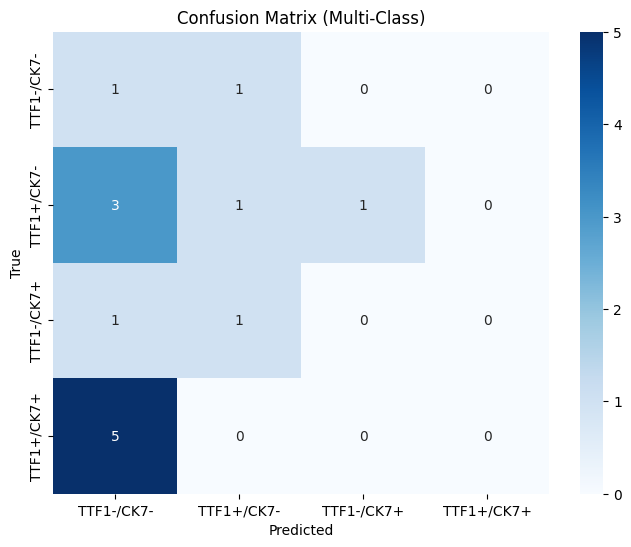


Classification Report:

              precision    recall  f1-score   support

  TTF1-/CK7-       0.10      0.50      0.17         2
  TTF1+/CK7-       0.33      0.20      0.25         5
  TTF1-/CK7+       0.00      0.00      0.00         2
  TTF1+/CK7+       0.00      0.00      0.00         5

    accuracy                           0.14        14
   macro avg       0.11      0.17      0.10        14
weighted avg       0.13      0.14      0.11        14



In [ ]:
loss, acc = model.evaluate(test_ds)
print(f"Test Loss: {loss:.4f}, Test Accuracy: {acc:.4f}")

y_true = []
y_pred_probs = []

for (vol, rad), lbl in test_ds:
    preds = model.predict((vol, rad), verbose=0)
    y_true.extend(lbl.numpy())
    y_pred_probs.extend(preds)

y_true = np.array(y_true)
y_pred_probs = np.array(y_pred_probs)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

class_names = ["TTF1-/CK7-", "TTF1+/CK7-", "TTF1-/CK7+", "TTF1+/CK7+"]

cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (Multi-Class)')
plt.show()

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred_classes, target_names=class_names, zero_division=0))

In [ ]:
print(f"Dimensiune actuală X_radio: {X_radio.shape}")

def multimodal_generator(indices, paths, radios, labels, augment=False):
    for i in indices:
        vol = load_ct_volume(paths[i])
        rad = radios[i]
        lbl = labels[i]

        if augment:
            vol = augment_volume(vol)

        yield (vol, rad), lbl

def create_dataset(indices, paths, radios, labels, training=False):
    ds = tf.data.Dataset.from_generator(
        lambda: multimodal_generator(indices, paths, radios, labels, augment=False),
        output_signature=(
            (
                tf.TensorSpec(shape=TARGET_SHAPE+(1,), dtype=tf.float32),
                tf.TensorSpec(shape=(radios.shape[1],), dtype=tf.float32)
            ),
            tf.TensorSpec(shape=(), dtype=tf.int32)
        )
    )

    if training:
        ds = ds.shuffle(len(indices))
        ds = ds.repeat()

    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = create_dataset(train_idx, ct_paths, X_radio, y_labels, training=True)
val_ds = create_dataset(val_idx, ct_paths, X_radio, y_labels, training=False)
test_ds = create_dataset(test_idx, ct_paths, X_radio, y_labels, training=False)

print("✅ Dataset-urile au fost actualizate corect (Input shape: 20).")
print("Acum poți rula celula de Antrenare (model.fit).")

Dimensiune actuală X_radio: (87, 20)
✅ Dataset-urile au fost actualizate corect (Input shape: 20).
Acum poți rula celula de Antrenare (model.fit).


In [ ]:
def build_tiny_model(radio_dim, input_shape):
    in_ct = tf.keras.Input(shape=input_shape, name="ct_input")

    x = tf.keras.layers.Conv3D(8, 3, padding="same", activation="relu")(in_ct)
    x = tf.keras.layers.MaxPooling3D(2)(x)

    x = tf.keras.layers.Conv3D(16, 3, padding="same", activation="relu")(x)
    x = tf.keras.layers.MaxPooling3D(2)(x)

    x = tf.keras.layers.Conv3D(32, 3, padding="same", activation="relu")(x)
    x = tf.keras.layers.GlobalAveragePooling3D()(x)

    x = tf.keras.layers.Dropout(0.5)(x)

    in_radio = tf.keras.Input(shape=(radio_dim,), name="radio_input")
    r = tf.keras.layers.Dense(32, activation="relu")(in_radio)
    r = tf.keras.layers.Dropout(0.5)(r)

    z = tf.keras.layers.Concatenate()([x, r])
    z = tf.keras.layers.Dense(32, activation="relu")(z)
    z = tf.keras.layers.Dropout(0.5)(z)

    out = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(z)

    model = tf.keras.Model(inputs=[in_ct, in_radio], outputs=out)
    return model

model = build_tiny_model(radio_dim=X_radio.shape[1], input_shape=TARGET_SHAPE+(1,))

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"]
)

model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ ct_input            │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 128, 1)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_14 (Conv3D)  │ (None, 128, 128,  │        224 │ ct_input[0][0]    │
│                     │ 128, 8)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_10    │ (None, 64, 64,    │          0 │ conv3d_14[0][0]   │
│ (MaxPooling3D)      │ 64, 8)            │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_15 (Conv3D)  │ (None, 64, 64,    │      3,472 │ max_pooling3d_10… │
│                     │ 64, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling3d_11    │ (None, 32, 32,    │          0 │ conv3d_15[0][0]   │
│ (MaxPooling3D)      │ 32, 16)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3d_16 (Conv3D)  │ (None, 32, 32,    │     13,856 │ max_pooling3d_11… │
│                     │ 32, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ radio_input         │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ conv3d_16[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_14 (Dense)    │ (None, 32)        │        672 │ radio_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_12          │ (None, 32)        │          0 │ global_average_p… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_13          │ (None, 32)        │          0 │ dense_14[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_4       │ (None, 64)        │          0 │ dropout_12[0][0], │
│ (Concatenate)       │                   │            │ dropout_13[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_15 (Dense)    │ (None, 32)        │      2,080 │ concatenate_4[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_14          │ (None, 32)        │          0 │ dense_15[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_16 (Dense)    │ (None, 4)         │        132 │ dropout_14[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 20,436 (79.83 KB)

 Trainable params: 20,436 (79.83 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from sklearn.utils import class_weight

unique_classes = np.unique(y_labels[train_idx])
class_weights_calc = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=unique_classes,
    y=y_labels[train_idx]
)
class_weight_dict = dict(zip(unique_classes, class_weights_calc))

print("Ponderi calculate:", class_weight_dict)

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, verbose=1, min_lr=1e-7),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_loss", save_best_only=True)
]

steps_per_epoch = len(train_idx) // BATCH_SIZE

print(f"Start Training pentru {EPOCHS} epoci...")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    steps_per_epoch=steps_per_epoch,
    callbacks=callbacks,
    class_weight=class_weight_dict
)

Ponderi calculate: {np.int32(0): np.float64(1.5), np.int32(1): np.float64(0.7142857142857143), np.int32(2): np.float64(1.875), np.int32(3): np.float64(0.7142857142857143)}
Start Training pentru 25 epoci...
Epoch 1/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 56s 937ms/step - loss: 1.4540 - sparse_categorical_accuracy: 0.2987 - val_loss: 1.5474 - val_sparse_categorical_accuracy: 0.2308 - learning_rate: 1.0000e-05
Epoch 2/25
 1/30 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - loss: 0.7806 - sparse_categorical_accuracy: 1.0000

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


30/30 ━━━━━━━━━━━━━━━━━━━━ 27s 936ms/step - loss: 1.6714 - sparse_categorical_accuracy: 0.3742 - val_loss: 1.5469 - val_sparse_categorical_accuracy: 0.2308 - learning_rate: 1.0000e-05
Epoch 3/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 25s 857ms/step - loss: 1.3572 - sparse_categorical_accuracy: 0.3721 - val_loss: 1.5466 - val_sparse_categorical_accuracy: 0.2308 - learning_rate: 1.0000e-05
Epoch 4/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 25s 859ms/step - loss: 1.6313 - sparse_categorical_accuracy: 0.1526 - val_loss: 1.5462 - val_sparse_categorical_accuracy: 0.2308 - learning_rate: 1.0000e-05
Epoch 5/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 25s 859ms/step - loss: 1.5623 - sparse_categorical_accuracy: 0.1561 - val_loss: 1.5455 - val_sparse_categorical_accuracy: 0.2308 - learning_rate: 1.0000e-05
Epoch 6/25
30/30 ━━━━━━━━━━━━━━━━━━━━ 27s 924ms/step - loss: 1.3941 - sparse_categorical_accuracy: 0.4345 - val_loss: 1.5451 - val_sparse_categorical_accuracy: 0.2308 - learning_rate: 1.0000e-05
Epoch 7/25
30/30 ━━━━━━━━━━━━━━━━━━━

In [ ]:
print(f"Generare predicții detaliate pentru cei {len(test_idx)} pacienți din setul de Test...")

patient_results = []
class_mapping = {
    0: "TTF1-/CK7-",
    1: "TTF1+/CK7-",
    2: "TTF1-/CK7+",
    3: "TTF1+/CK7+"
}

for idx in test_idx:
    patient_code = codes[idx]
    true_label_id = y_labels[idx]

    vol = load_ct_volume(ct_paths[idx])
    rad = X_radio[idx]

    vol_batch = np.expand_dims(vol, axis=0)
    rad_batch = np.expand_dims(rad, axis=0)

    pred_probs = model.predict([vol_batch, rad_batch], verbose=0)
    pred_label_id = np.argmax(pred_probs)
    confidence = np.max(pred_probs)

    is_correct = (true_label_id == pred_label_id)

    patient_results.append({
        "Code": patient_code,
        "True ID": true_label_id,
        "Pred ID": pred_label_id,
        "True Label": class_mapping[true_label_id],
        "Pred Label": class_mapping[pred_label_id],
        "Correct": "correct" if is_correct else "false",
        "Conf. (%)": f"{confidence * 100:.1f}%"
    })

df_eval = pd.DataFrame(patient_results)

def highlight_errors(s):
    return ['background-color: #ffcccc' if v == 'false' else 'background-color: #ccffcc' for v in s]

print("\nRezultate Detaliate:")
display(df_eval.style.apply(highlight_errors, subset=['Correct']))

csv_path = f"{BASE_DIR}/test_results_detailed.csv"
df_eval.to_csv(csv_path, index=False)
print(f"\nRaport salvat în: {csv_path}")

Generare predicții detaliate pentru cei 14 pacienți din setul de Test...

Rezultate Detaliate:


,Code,True ID,Pred ID,True Label,Pred Label,Correct,Conf. (%)
0,74111,3,3,TTF1+/CK7+,TTF1+/CK7+,correct,30.1%
1,25111,0,0,TTF1-/CK7-,TTF1-/CK7-,correct,33.1%
2,10111,1,0,TTF1+/CK7-,TTF1-/CK7-,false,35.7%
3,73111,0,0,TTF1-/CK7-,TTF1-/CK7-,correct,30.9%
4,8011,3,3,TTF1+/CK7+,TTF1+/CK7+,correct,32.2%
5,63111,2,0,TTF1-/CK7+,TTF1-/CK7-,false,64.9%
6,4111,1,3,TTF1+/CK7-,TTF1+/CK7+,false,30.7%
7,98011,3,0,TTF1+/CK7+,TTF1-/CK7-,false,33.8%
8,32111,2,0,TTF1-/CK7+,TTF1-/CK7-,false,37.8%
9,102111,1,0,TTF1+/CK7-,TTF1-/CK7-,false,29.2%



Raport salvat în: /content/drive/MyDrive/Colab Notebooks/lung_cancer/test_results_detailed.csv


7/7 ━━━━━━━━━━━━━━━━━━━━ 5s 713ms/step - loss: 1.3834 - sparse_categorical_accuracy: 0.5277
Test Loss: 1.4680, Test Accuracy: 0.2857


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


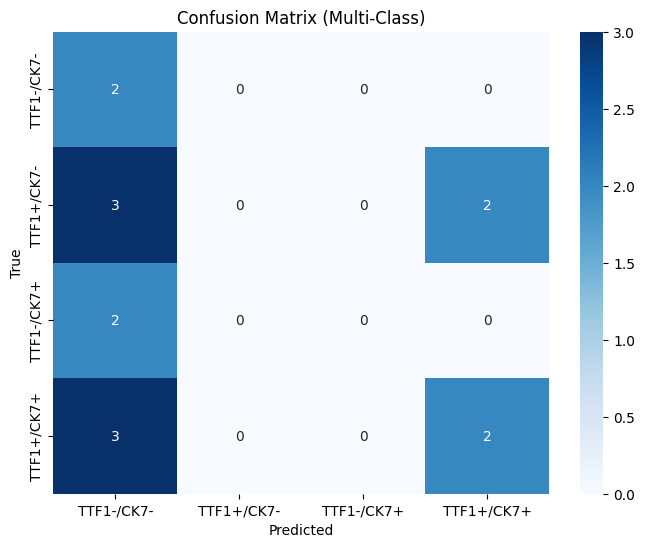


Classification Report:

              precision    recall  f1-score   support

  TTF1-/CK7-       0.20      1.00      0.33         2
  TTF1+/CK7-       0.00      0.00      0.00         5
  TTF1-/CK7+       0.00      0.00      0.00         2
  TTF1+/CK7+       0.50      0.40      0.44         5

    accuracy                           0.29        14
   macro avg       0.17      0.35      0.19        14
weighted avg       0.21      0.29      0.21        14



In [ ]:
loss, acc = model.evaluate(test_ds)
print(f"Test Loss: {loss:.4f}, Test Accuracy: {acc:.4f}")

y_true = []
y_pred_probs = []

for (vol, rad), lbl in test_ds:
    preds = model.predict((vol, rad), verbose=0)
    y_true.extend(lbl.numpy())
    y_pred_probs.extend(preds)

y_true = np.array(y_true)
y_pred_probs = np.array(y_pred_probs)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

class_names = ["TTF1-/CK7-", "TTF1+/CK7-", "TTF1-/CK7+", "TTF1+/CK7+"]

cm = confusion_matrix(y_true, y_pred_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (Multi-Class)')
plt.show()

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred_classes, target_names=class_names, zero_division=0))

In [ ]:
!pip install xgboost

🚀 Start antrenare XGBoost pe Radiomics...
[0]	validation_0-mlogloss:1.34732	validation_1-mlogloss:1.38925


/usr/local/lib/python3.12/dist-packages/xgboost/callback.py:386: UserWarning: [09:44:56] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "use_label_encoder" } are not used.

  self.starting_round = model.num_boosted_rounds()


[46]	validation_0-mlogloss:0.57562	validation_1-mlogloss:1.42721

--- Evaluare pe Test Set ---
XGBoost Accuracy: 0.3571

Classification Report:

              precision    recall  f1-score   support

  TTF1-/CK7-       0.50      0.50      0.50         2
  TTF1+/CK7-       0.40      0.40      0.40         5
  TTF1-/CK7+       0.33      1.00      0.50         2
  TTF1+/CK7+       0.00      0.00      0.00         5

    accuracy                           0.36        14
   macro avg       0.31      0.47      0.35        14
weighted avg       0.26      0.36      0.29        14



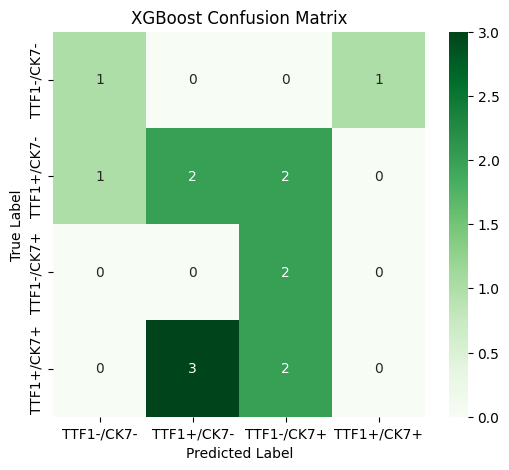

In [ ]:
import xgboost as xgb
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.utils.class_weight import compute_sample_weight
import matplotlib.pyplot as plt
import seaborn as sns

X_train_rad = X_radio[train_idx]
y_train_rad = y_labels[train_idx]

X_val_rad = X_radio[val_idx]
y_val_rad = y_labels[val_idx]

X_test_rad = X_radio[test_idx]
y_test_rad = y_labels[test_idx]

sample_weights = compute_sample_weight(
    class_weight='balanced',
    y=y_train_rad
)

model_xgb = xgb.XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='multi:softprob',
    num_class=NUM_CLASSES,
    eval_metric='mlogloss',
    use_label_encoder=False,
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=30
)

print("🚀 Start antrenare XGBoost pe Radiomics...")
model_xgb.fit(
    X_train_rad,
    y_train_rad,
    sample_weight=sample_weights,
    eval_set=[(X_train_rad, y_train_rad), (X_val_rad, y_val_rad)],
    verbose=50

)

print("\n--- Evaluare pe Test Set ---")
y_pred_xgb = model_xgb.predict(X_test_rad)
acc = accuracy_score(y_test_rad, y_pred_xgb)

print(f"XGBoost Accuracy: {acc:.4f}")
print("\nClassification Report:\n")
print(classification_report(y_test_rad, y_pred_xgb, target_names=class_names, zero_division=0))

cm = confusion_matrix(y_test_rad, y_pred_xgb)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=class_names, yticklabels=class_names)
plt.title('XGBoost Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

In [ ]:
def build_micro_ct_model(input_shape):
    in_ct = tf.keras.Input(shape=input_shape, name="ct_input")

    x = tf.keras.layers.Conv3D(8, 3, padding="same")(in_ct)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.MaxPooling3D(2)(x)

    x = tf.keras.layers.Conv3D(16, 3, padding="same")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.MaxPooling3D(2)(x)

    x = tf.keras.layers.Conv3D(32, 3, padding="same")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.GlobalAveragePooling3D()(x)

    x = tf.keras.layers.Dropout(0.4)(x)
    x = tf.keras.layers.Dense(32, activation="relu")(x)

    out = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax", name="class_output")(x)

    model = tf.keras.Model(inputs=in_ct, outputs=out)
    return model

model_ct = build_micro_ct_model(input_shape=(128, 128, 128, 1))
model_ct.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["sparse_categorical_accuracy"]
)
model_ct.summary()

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ct_input (InputLayer)           │ (None, 128, 128, 128,  │             0 │
│                                 │ 1)                     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_24 (Conv3D)              │ (None, 128, 128, 128,  │           224 │
│                                 │ 8)                     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 128, 128, 128,  │            32 │
│ (BatchNormalization)            │ 8)                     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_15 (Activation)      │ (None, 128, 128, 128,  │             0 │
│                                 │ 8)                     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_17 (MaxPooling3D) │ (None, 64, 64, 64, 8)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_25 (Conv3D)              │ (None, 64, 64, 64, 16) │         3,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 64, 64, 64, 16) │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_16 (Activation)      │ (None, 64, 64, 64, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_18 (MaxPooling3D) │ (None, 32, 32, 32, 16) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_26 (Conv3D)              │ (None, 32, 32, 32, 32) │        13,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 32, 32, 32, 32) │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_17 (Activation)      │ (None, 32, 32, 32, 32) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling3d_7      │ (None, 32)             │             0 │
│ (GlobalAveragePooling3D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_output (Dense)            │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,964 (74.08 KB)

 Trainable params: 18,852 (73.64 KB)

 Non-trainable params: 112 (448.00 B)

In [ ]:
def ct_only_generator(indices, paths, labels, augment=False):
    for i in indices:
        vol = load_ct_volume(paths[i])
        lbl = labels[i]

        if augment:
            vol = augment_volume(vol)

        yield vol, lbl

def create_ct_dataset(indices, paths, labels, training=False):
    ds = tf.data.Dataset.from_generator(
        lambda: ct_only_generator(indices, paths, labels, augment=False),
        output_signature=(
            tf.TensorSpec(shape=TARGET_SHAPE+(1,), dtype=tf.float32),
            tf.TensorSpec(shape=(), dtype=tf.int32)
        )
    )

    if training:
        ds = ds.shuffle(len(indices))

    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds_ct = create_ct_dataset(train_idx, ct_paths, y_labels, training=True)
val_ds_ct = create_ct_dataset(val_idx, ct_paths, y_labels, training=False)
test_ds_ct = create_ct_dataset(test_idx, ct_paths, y_labels, training=False)

print("Dataset-uri CT-Only create!")

Dataset-uri CT-Only create!


In [ ]:
callbacks_ct = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(f"{BASE_DIR}/model_ct_only.keras", monitor="val_loss", save_best_only=True)
]

print("Start Training CT-Only Model...")
history_ct = model_ct.fit(
    train_ds_ct,
    validation_data=val_ds_ct,
    epochs=20,
    callbacks=callbacks_ct,
    class_weight=class_weight_dict
)

Start Training CT-Only Model...
Epoch 1/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 34s 266ms/step - loss: 1.5495 - sparse_categorical_accuracy: 0.1197 - val_loss: 1.3945 - val_sparse_categorical_accuracy: 0.1538 - learning_rate: 1.0000e-04
Epoch 2/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 40s 302ms/step - loss: 1.5610 - sparse_categorical_accuracy: 0.1842 - val_loss: 1.3993 - val_sparse_categorical_accuracy: 0.1538 - learning_rate: 1.0000e-04
Epoch 3/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 28s 215ms/step - loss: 1.5597 - sparse_categorical_accuracy: 0.1938 - val_loss: 1.4011 - val_sparse_categorical_accuracy: 0.1538 - learning_rate: 1.0000e-04
Epoch 4/20
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - loss: 1.5502 - sparse_categorical_accuracy: 0.1520
Epoch 4: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
30/30 ━━━━━━━━━━━━━━━━━━━━ 28s 223ms/step - loss: 1.5476 - sparse_categorical_accuracy: 0.1519 - val_loss: 1.4007 - val_sparse_categorical_accuracy: 0.1538 - learning_rate: 1.0000e-04
Epoch 5/20
30/30 ━━

In [ ]:
X_test_vol_array = []
for idx in test_idx:
    vol = load_ct_volume(ct_paths[idx])
    X_test_vol_array.append(vol)
X_test_vol_array = np.array(X_test_vol_array)

probs_cnn = model_ct.predict(X_test_vol_array, verbose=0)

Generare predicții pentru Ensemble...

 Cel mai bun rezultat Ensemble:
Pondere CNN: 0.00
Pondere XGBoost: 1.00
Acuratețe Finală: 0.3571

--- Raport de Clasificare (Ensemble) ---
              precision    recall  f1-score   support

  TTF1-/CK7-       0.50      0.50      0.50         2
  TTF1+/CK7-       0.40      0.40      0.40         5
  TTF1-/CK7+       0.33      1.00      0.50         2
  TTF1+/CK7+       0.00      0.00      0.00         5

    accuracy                           0.36        14
   macro avg       0.31      0.47      0.35        14
weighted avg       0.26      0.36      0.29        14



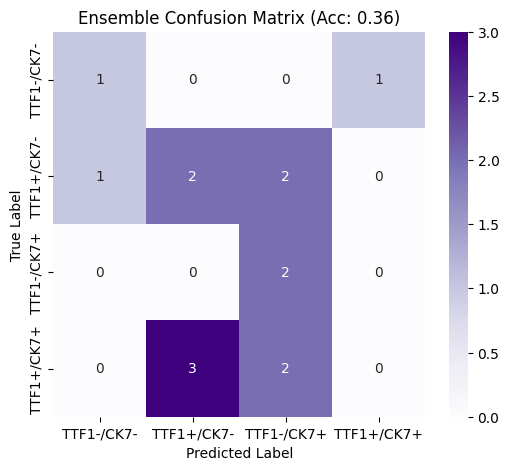

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("Generare predicții pentru Ensemble...")

probs_xgb = model_xgb.predict_proba(X_test_rad)

X_test_vol = []
X_test_rad_cnn = []

for idx in test_idx:
    vol = load_ct_volume(ct_paths[idx])
    X_test_vol.append(vol)
    X_test_rad_cnn.append(X_radio[idx])

X_test_vol = np.array(X_test_vol)
X_test_rad_cnn = np.array(X_test_rad_cnn)

probs_cnn = model.predict([X_test_vol, X_test_rad_cnn], verbose=0)

best_acc = 0
best_weight = 0
best_preds = []

for w in np.linspace(0, 1, 21):
    weighted_probs = (w * probs_cnn) + ((1 - w) * probs_xgb)

    final_preds = np.argmax(weighted_probs, axis=1)

    acc = accuracy_score(y_test_rad, final_preds)

    if acc > best_acc:
        best_acc = acc
        best_weight = w
        best_preds = final_preds

print(f"\n Cel mai bun rezultat Ensemble:")
print(f"Pondere CNN: {best_weight:.2f}")
print(f"Pondere XGBoost: {1 - best_weight:.2f}")
print(f"Acuratețe Finală: {best_acc:.4f}")

print("\n--- Raport de Clasificare (Ensemble) ---")
print(classification_report(y_test_rad, best_preds, target_names=class_names, zero_division=0))

plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test_rad, best_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=class_names, yticklabels=class_names)
plt.title(f'Ensemble Confusion Matrix (Acc: {best_acc:.2f})')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

In [ ]:
print("Evaluare CNN pe Test Set...")
loss, acc = model_ct.evaluate(test_ds_ct)
print(f"Acuratețe CNN CT-Only: {acc:.4f}")

preds = model_ct.predict(test_ds_ct)
pred_classes = np.argmax(preds, axis=1)
print("Predicțiile CNN:", pred_classes)
print("Etichetele Reale:", y_labels[test_idx])

Evaluare CNN pe Test Set...
7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 838ms/step - loss: 1.3922 - sparse_categorical_accuracy: 0.2795
Acuratețe CNN CT-Only: 0.1429


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


7/7 ━━━━━━━━━━━━━━━━━━━━ 6s 708ms/step
Predicțiile CNN: [0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Etichetele Reale: [3 0 1 0 3 2 1 3 2 1 1 3 1 3]
